xu: [0.         0.08327551 0.17491111 0.26815808 0.36189724 0.45506358
 0.54715424 0.63886539 0.73010428 0.8207937  0.91085569 1.00019714]
xl: [0.         0.09854267 0.18872525 0.27729646 0.36537549 0.45402733
 0.54375485 0.63386189 0.72444118 0.81556993 0.90732613 0.99980286]
Number of upper points: 12
Number of lower points: 12


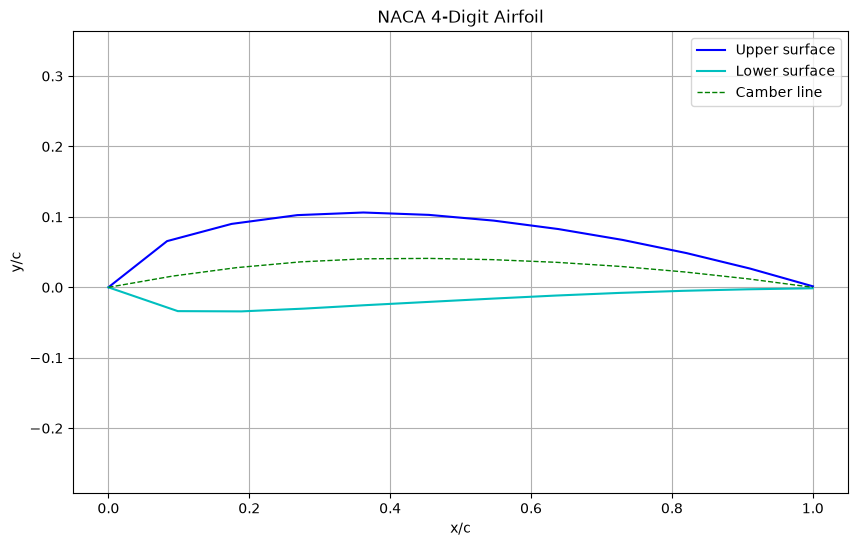

In [27]:
import numpy as np
import matplotlib.pyplot as plt

rng= np.random.default_rng()

m=rng.uniform(0.01,0.06)
p=rng.uniform(0.20 , 0.60)
t=rng.uniform(0.08,0.18)

n=12
x=np.linspace(0,1,n)

yt = 5 * t * ( 0.2969 * np.sqrt(x)- 0.1260 * x- 0.3516 * x**2+ 0.2843 * x**3 - 0.1015 * x**4)

yc = np.zeros(n)
dyc_dx=np.zeros(n)


for i in range(len(x)):
    if x[i] <= p:
        yc[i] = (m / p**2) * (2 * p * x[i] - x[i]**2)
        dyc_dx[i] = (2 * m / p**2) * (p - x[i])
    else:
        yc[i] = (m / (1 - p)**2) * ((1 - 2 * p) + 2 * p * x[i] - x[i]**2)
        dyc_dx[i] = (2 * m / (1 - p)**2) * (p - x[i])

   
theta = np.arctan(dyc_dx)

xu = x - yt * np.sin(theta)
yu = yc + yt * np.cos(theta)

xl = x + yt * np.sin(theta)
yl = yc - yt * np.cos(theta)

print("xu:", xu)
print("xl:", xl)
print("Number of upper points:", len(xu))
print("Number of lower points:", len(xl))

plt.figure(figsize=(10, 6))

plt.plot(xu, yu, 'b-', linewidth=1.5, label='Upper surface')
plt.plot(xl, yl, 'c-', linewidth=1.5, label='Lower surface')
plt.plot(x, yc, 'g--', linewidth=1, label='Camber line')

plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title('NACA 4-Digit Airfoil')
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

The first part of the problem statement begins with generating a NACA 4 series unsymmetric airfoil. For this first we define the varaibles for maximum camber , location of maximum camber , thickness ratio and also specify the range for those values respectively as we are usinng random no. generator.
The numerical method begins by generating \(N\) points between zero and one and evaluating the NACA thickness distribution and camber-line equations at these points. The upper and lower surface coordinates are then obtained using the local camber-line angle. These \(N\) surface points are used as the interpolation data.
After generating N points we give the equation and plot the airfoil

$$
y_t=5t\left(0.2969\sqrt{x}-0.1260x-0.3516x^2+0.2843x^3-0.1015x^4\right).
$$

The camber line is defined separately before and after the location of maximum camber. For \(0\leq x\leq p\),

$$
y_c=\frac{m}{p^2}(2px-x^2),
$$

while for \(p<x\leq1\),

$$
y_c=\frac{m}{(1-p)^2}\left[(1-2p)+2px-x^2\right].
$$

The corresponding camber-line slope is obtained from

$$
\frac{dy_c}{dx}=
\frac{2m}{p^2}(p-x)
$$

for the forward section and

$$
\frac{dy_c}{dx}=
\frac{2m}{(1-p)^2}(p-x)
$$

for the rear section. The local inclination of the camber line is then given by

$$
\theta=\tan^{-1}\left(\frac{dy_c}{dx}\right).
$$

Using this angle, the coordinates of the upper and lower surfaces are calculated as

$$
x_u=x-y_t\sin\theta,\qquad
y_u=y_c+y_t\cos\theta
$$

and

$$
x_l=x+y_t\sin\theta,\qquad
y_l=y_c-y_t\cos\theta.
$$

These equations provide the original airfoil geometry against which the interpolated geometry is compared.


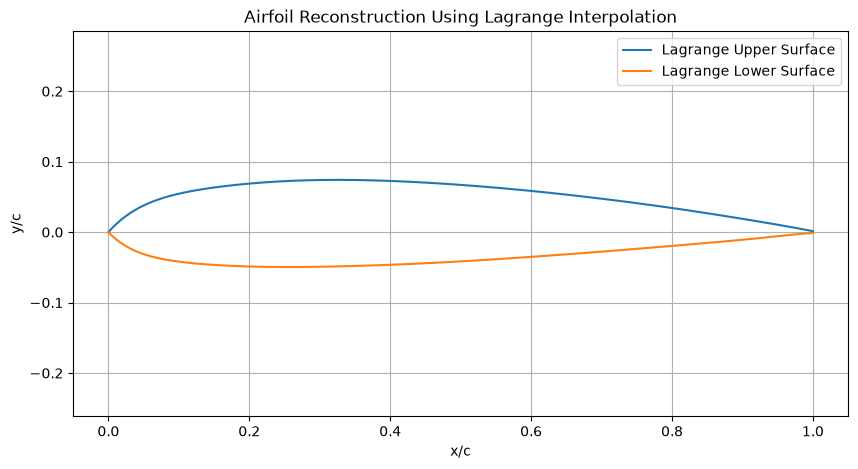

In [23]:
def lagrang(x_lag, y_lag, n_lag, xx):
    result=0.0

    for i in range(n_lag):

        product = y_lag[i]

        for j in range(n_lag):

            if i != j:

                product = product * ( (xx - x_lag[j]) / (x_lag[i] - x_lag[j]))

        result = result + product

    return result
xx=np.linspace(0,1,500)

yu_lagrang=np.zeros(len(xx))
yl_lagrang=np.zeros(len(xx))


for k in range(len(xx)):
    yu_lagrang[k] = lagrang(xu, yu, len(xu), xx[k])
    yl_lagrang[k] = lagrang(xl, yl, len(xl), xx[k])


plt.figure(figsize=(10, 5))

plt.plot(xx, yu_lagrang, label="Lagrange Upper Surface")
plt.plot(xx, yl_lagrang, label="Lagrange Lower Surface")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("Airfoil Reconstruction Using Lagrange Interpolation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


## Lagrange interpolation

Once we specify the basic equations of an airfoil , we further move on to lagrnage interpolation .
The reconstruction is performed using the Lagrange interpolation polynomial,
Basically what lagrange interpolation does is that  it divides the segment in to number of small parts (in this case 500) and then while plotting , it connects those small segments, as a result of that we get a more smooth curve and very little sharp edges .

To begin with we define the lagrange function and name the new x-axis on which we want the points , after that we specify the exact formula for lagrange interpolation as specified below . Now our basic framework for  interpolation is completed , then we apply this formulaes on the upper surface and lower surface of an airfoil by using original airfoil data or the variables(xu, xl , yu , yl). 
Once this is completed we get the new  values and location of at the new x axis we defined , as in this case the xx axis. Then these points are taken and plotted to get an airfoil . 
$$
P(x)=\sum_{i=0}^{N-1}y_i
\prod_{\substack{j=0\\j\neq i}}^{N-1}
\frac{x-x_j}{x_i-x_j}.
$$

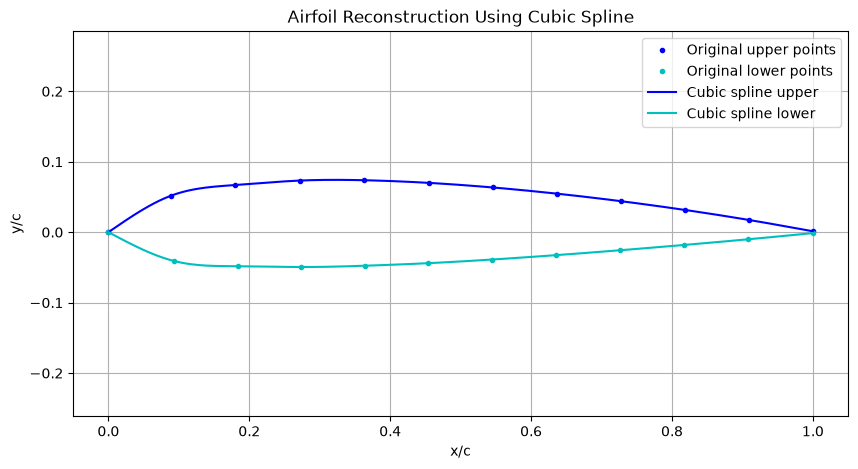

In [24]:

def cubic_spline(x, y, xx):

    n = len(x)

    
    h = np.diff(x)

    A = np.zeros((n, n))
    B = np.zeros(n)

    A[0, 0] = 1
    A[n-1, n-1] = 1

    for i in range(1, n-1):

        A[i, i-1] = h[i-1]
        A[i, i] = 2 * (h[i-1] + h[i])
        A[i, i+1] = h[i]

        B[i] = 6 * (
            (y[i+1] - y[i]) / h[i]
            - (y[i] - y[i-1]) / h[i-1]
        )

  
    M = np.linalg.solve(A, B)


    indices = np.searchsorted(x, xx, side="right") - 1
    indices = np.clip(indices, 0, n-2)

    xi = x[indices]
    xi1 = x[indices + 1]

    yi = y[indices]
    yi1 = y[indices + 1]

    hi = h[indices]

    Mi = M[indices]
    Mi1 = M[indices + 1]

    yy = (
        Mi * (xi1 - xx)**3 / (6 * hi)
        + Mi1 * (xx - xi)**3 / (6 * hi)
        + (yi - Mi * hi**2 / 6) * (xi1 - xx) / hi
        + (yi1 - Mi1 * hi**2 / 6) * (xx - xi) / hi
    )

    return yy



upper_order = np.argsort(xu)
xu_sorted = xu[upper_order]
yu_sorted = yu[upper_order]

lower_order = np.argsort(xl)
xl_sorted = xl[lower_order]
yl_sorted = yl[lower_order]


xu_sorted, upper_idx = np.unique(xu_sorted, return_index=True)
yu_sorted = yu_sorted[upper_idx]

xl_sorted, lower_idx = np.unique(xl_sorted, return_index=True)
yl_sorted = yl_sorted[lower_idx]


xx = np.linspace(0, 1, 500)

yu_spline = cubic_spline(xu_sorted, yu_sorted, xx)
yl_spline = cubic_spline(xl_sorted, yl_sorted, xx)

plt.figure(figsize=(10, 5))

plt.plot(xu, yu, 'bo', markersize=3, label="Original upper points")
plt.plot(xl, yl, 'co', markersize=3, label="Original lower points")

plt.plot(xx, yu_spline, 'b-', label="Cubic spline upper")
plt.plot(xx, yl_spline, 'c-', label="Cubic spline lower")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("Airfoil Reconstruction Using Cubic Spline")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

## Cubic spline

The cubic spline interpolation procedure is implemented using the following steps:

Read the discrete (x)- and (y)-coordinates of the airfoil surface.

Arrange the coordinates in strictly increasing order of (x), ensuring that no duplicate interpolation coordinates are present.

Calculate the interval widths using (h_i=x_{i+1}-x_i).

Apply the natural boundary conditions by setting the endpoint second derivatives to zero.

Construct and solve the tridiagonal system to determine the second derivatives at the interior points.

Identify the interval containing each required interpolation coordinate.

Evaluate the corresponding cubic spline polynomial to obtain the interpolated ordinate.

Repeat the procedure independently for the upper and lower surfaces.

Plot the interpolated coordinates to reconstruct the complete airfoil profile.

"$$S_i(x) = \\frac{M_i}{6h_i}(x_{i+1}-x)^3 + \\frac{M_{i+1}}{6h_i}(x-x_i)^3 + \\left(\\frac{y_i}{h_i} - \\frac{M_i h_i}{6}\\right)(x_{i+1}-x) + \\left(\\frac{y_{i+1}}{h_i} - \\frac{M_{i+1} h_i}{6}\\right)(x-x_i)$$\n",
    "\n",
    "\n",
    "The unknown $M_i$ values are found by enforcing smooth (matching curvature) connections between adjacent pieces at every interior point, which leads to the following system of equations:\n",
    "\n",
    "$$h_{i-1} M_{i-1} + 2(h_{i-1}+h_i) M_i + h_i M_{i+1} = 6\\left(\\frac{y_{i+1}-y_i}{h_i} - \\frac{y_i - y_{i-1}}{h_{i-1}}\\right)$$\n",
    "\n",
    "For a **natural cubic spline**, curvature is set to zero at the endpoints:\n",
    "\n",
    "$$M_0 = 0, \\qquad M_{n} = 0$$"


In [25]:
x_ref = xx.copy()

yt_ref = 5 * t * (0.2969 * np.sqrt(x_ref)- 0.1260 * x_ref- 0.3516 * x_ref**2+ 0.2843 * x_ref**3- 0.1015 * x_ref**4)

yc_ref = np.zeros(len(x_ref))
dyc_dx_ref = np.zeros(len(x_ref))

for i in range(len(x_ref)):
    if x_ref[i] <= p:
        yc_ref[i] = (m / p**2) * (2 * p * x_ref[i] - x_ref[i]**2)
        
        dyc_dx_ref[i] = (2 * m / p**2) * (p - x_ref[i])
        
    else:
        yc_ref[i] = (m / (1 - p)**2) * ((1 - 2 * p) + 2 * p * x_ref[i]- x_ref[i]**2)
        
        dyc_dx_ref[i] = (2 * m / (1 - p)**2) * (p - x_ref[i])

theta_ref = np.arctan(dyc_dx_ref)


yu_true = yc_ref + yt_ref * np.cos(theta_ref)
yl_true = yc_ref - yt_ref * np.cos(theta_ref)


def calculate_error(y_true, y_reconstructed):
    error = y_true - y_reconstructed

    max_error = np.max(np.abs(error))
    rms_error = np.sqrt(np.mean(error**2))

    return max_error, rms_error



max_lag_upper, rms_lag_upper = calculate_error(yu_true, yu_lagrang)

max_lag_lower, rms_lag_lower = calculate_error(yl_true, yl_lagrang)


max_spline_upper, rms_spline_upper = calculate_error(yu_true, yu_spline)

max_spline_lower, rms_spline_lower = calculate_error(yl_true, yl_spline)


y_true_all = np.concatenate([yu_true, yl_true])

y_lagrange_all = np.concatenate([yu_lagrang, yl_lagrang])

y_spline_all = np.concatenate([yu_spline, yl_spline])

max_lag, rms_lag = calculate_error(y_true_all, y_lagrange_all)

max_spline, rms_spline = calculate_error(y_true_all, y_spline_all)


print("\n LAGRANGE INTERPOLATION")
print(f"Upper surface maximum error: {max_lag_upper:.8e}")
print(f"Upper surface RMS error:     {rms_lag_upper:.8e}")
print(f"Lower surface maximum error: {max_lag_lower:.8e}")
print(f"Lower surface RMS error:     {rms_lag_lower:.8e}")
print(f"Overall maximum error:       {max_lag:.8e}")
print(f"Overall RMS error:           {rms_lag:.8e}")

print("\n CUBIC SPLINE INTERPOLATION")
print(f"Upper surface maximum error: {max_spline_upper:.8e}")
print(f"Upper surface RMS error:     {rms_spline_upper:.8e}")
print(f"Lower surface maximum error: {max_spline_lower:.8e}")
print(f"Lower surface RMS error:     {rms_spline_lower:.8e}")
print(f"Overall maximum error:       {max_spline:.8e}")
print(f"Overall RMS error:           {rms_spline:.8e}")



 LAGRANGE INTERPOLATION
Upper surface maximum error: 7.73549150e-03
Upper surface RMS error:     1.23238234e-03
Lower surface maximum error: 7.44785675e-03
Lower surface RMS error:     1.19564656e-03
Overall maximum error:       7.73549150e-03
Overall RMS error:           1.21415340e-03

 CUBIC SPLINE INTERPOLATION
Upper surface maximum error: 1.18675462e-02
Upper surface RMS error:     2.41860291e-03
Lower surface maximum error: 1.23142794e-02
Lower surface RMS error:     2.58023283e-03
Overall maximum error:       1.23142794e-02
Overall RMS error:           2.50072405e-03


## Error  calculation

The objective is to evaluate the accuracy of airfoil reconstruction using Lagrange polynomial interpolation and cubic spline interpolation by comparing their reconstructed coordinates with the reference NACA airfoil geometry.

The reference airfoil coordinates are calculated using the NACA four-digit airfoil equations. 
The thickness distribution (\(y_t\)) and mean camber line (\(y_c\)) are evaluated using the randomly generated parameters \(m\), \(p\), and \(t\), representing maximum camber, its location, and maximum thickness, respectively. The slope of the camber line is used to calculate the local angle \(\theta\).

The upper and lower surface coordinates are obtained as

\[
y_u=y_c+y_t\cos\theta
\]

\[
y_l=y_c-y_t\cos\theta
\]

These coordinates serve as the reference values for error analysis.

## 3. Error Calculation Methods


**Maximum Absolute Error:** This represents the largest absolute difference between the reference and reconstructed coordinates.

\[
E_{\max}=\max_i|y_{i,\text{true}}-y_{i,\text{reconstructed}}|
\]

**Root Mean Square (RMS) Error:** This measures the overall deviation of the reconstructed coordinates from the reference values.

\[
E_{\mathrm{RMS}}=
\sqrt{\frac{1}{N}\sum_{i=1}^{N}
(y_{i,\text{true}}-y_{i,\text{reconstructed}})^2}
\]

The errors are calculated separately for the upper and lower surfaces. The coordinates of both surfaces are then concatenated to determine the overall maximum and RMS errors for each interpolation method.
A smaller maximum error indicates better accuracy at the worst-matching point, while a smaller RMS error indicates better overall agreement with the reference geometry. 
We applied these two methods to compare the  results  overall and also to  make the error as minimum . 


## 4. Results and Discussion

The original airfoil geometry and the Lagrange reconstructed geometry are plotted  to get the interpolation. For the selected number of data points, the reconstructed surface follows the original NACA airfoil closely when the interpolation points are distributed. The maximum error indicates the location at which the reconstructed surface deviates most from the original geometry, whereas the RMS error represents the average magnitude of the deviation over the complete surface.

The accuracy of the reconstruction is strongly dependent on the number and distribution of the interpolation points. The present calculation uses uniformly spaced points generated along the chord.

Increasing the number of points will provide a better representation of the airfoil,it will keep on smoothening and an accurate and smooth curve will be obtained at the end.
                        
## 5. Summary and Conclusion

A cambered NACA airfoil was generated using randomly selected camber, camber-location, and thickness parameters. The standard NACA thickness distribution and camber-line equations were used to obtain the upper and lower surface coordinates. These coordinates were then reconstructed using Lagrange polynomial interpolation and compared with the original airfoil geometry.

The reconstruction accuracy was quantified using maximum and RMS errors for both the upper and lower surfaces. The study demonstrates that interpolation accuracy depends not only on the number of available geometry points but also on their spatial distribution. Uniform spacing provides a basic reconstruction, while an appropriate non-uniform distribution such as cosine spacing can provide improved resolution near regions of high curvature. Hence, careful selection of the number and spacing of interpolation points is important for obtaining an accurate and smooth numerical reconstruction of an airfoil.
